# Lumen · Index and ranking mechanics

A reproducible experiment using the same application modules as the running project. Run all cells in order. Demonstration data and fixed corpora are not evidence of production performance.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'app').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Inspect the inverted index

Each posting contains the original token positions in title plus content. Inspect actual postings rather than using an external search service.

In [2]:
import json,math,time,sys
from app.domain.ranking import Index,tokenize
corpus=json.loads((ROOT/'data/corpus.json').read_text())
documents=[dict(id=str(i+1),**doc) for i,doc in enumerate(corpus)]
index=Index(documents)
display(pd.DataFrame([{'term':term,'document_frequency':len(postings),'positions':postings} for term,postings in index.postings.items() if term in {'retrieval','index','bm25','search'}]))
print('Documents:',len(index.documents),'unique terms:',len(index.postings),'average document tokens:',index.average)

Documents: 12 unique terms: 213 average document tokens: 27.083333333333332


,term,document_frequency,positions
0,retrieval,3,"{'1': [1, 4], '5': [3, 14, 30], '7': [10]}"
1,index,2,"{'1': [13], '11': [15]}"
2,bm25,1,"{'2': [0, 3, 22]}"
3,search,4,"{'2': [27], '5': [1, 7, 25], '11': [0], '12': ..."


## BM25 term contributions

Independently reconstruct the implemented BM25 formula for a chosen query, then compare the rounded document totals with the application ranker.

In [3]:
query='information retrieval ranking';rows=[];n=len(documents)
for term in tokenize(query):
    posting=index.postings.get(term,{})
    for key,positions in posting.items():
        tf=len(positions);df=len(posting);length=index.lengths[key]
        idf=math.log(1+(n-df+.5)/(df+.5))
        denominator=tf+1.5*(1-.75+.75*length/index.average)
        rows.append({'document':key,'term':term,'tf':tf,'df':df,'length':length,'idf':idf,'contribution':idf*tf*2.5/denominator})
contributions=pd.DataFrame(rows);display(contributions.round(4))
manual=contributions.groupby('document').contribution.sum().round(5).to_dict()
ranked=index.search(query)
assert all(manual[str(hit['id'])]==hit['score'] for hit in ranked)
display(pd.DataFrame(ranked)[['id','title','score']])

,document,term,tf,df,length,idf,contribution
0,1,information,2,1,27,2.1595,3.0880
1,1,retrieval,2,3,27,1.3122,1.8764
2,5,retrieval,3,3,31,1.3122,2.1107
3,7,retrieval,1,3,24,1.3122,1.3830
4,1,ranking,1,3,27,1.3122,1.3140
5,2,ranking,2,3,28,1.3122,1.8544
6,12,ranking,2,3,27,1.3122,1.8764


,id,title,score
0,1,Information retrieval foundations,6.27845
1,5,Vector search and retrieval augmented generation,2.11067
2,12,Search ranking evaluation,1.87641
3,2,BM25 ranking explained,1.85438
4,7,Multi agent research systems,1.38304


## Phrase order and tokenizer boundaries

Phrase matching must preserve adjacency and order. Document the ASCII tokenizer limitation explicitly, including punctuation and accented words.

In [4]:
fixtures=Index([{'id':1,'title':'One','content':'machine learning systems'},
                {'id':2,'title':'Two','content':'learning machine systems'},
                {'id':3,'title':'Three','content':'machine useful learning systems'}])
phrase_rows=[]
for phrase in ['"machine learning"','"learning machine"','machine learning','"machine useful learning"']:
    phrase_rows.append({'query':phrase,'matched_ids':[h['id'] for h in fixtures.search(phrase)]})
display(pd.DataFrame(phrase_rows))
assert [h['id'] for h in fixtures.search('"machine learning"')]==[1]
display(pd.DataFrame({'input':['BM25!!!','Café café','machine-learning'],
                      'tokens':[tokenize(t) for t in ['BM25!!!','Café café','machine-learning']]}))
print('Non-ASCII normalization and linguistic stemming are future work, not current capabilities.')

Non-ASCII normalization and linguistic stemming are future work, not current capabilities.


,query,matched_ids
0,"""machine learning""",[1]
1,"""learning machine""",[2]
2,machine learning,"[1, 2, 3]"
3,"""machine useful learning""",[3]


,input,tokens
0,BM25!!!,[bm25]
1,Café café,"[caf, caf]"
2,machine-learning,"[machine, learning]"


## Term-frequency saturation

A controlled one-term collection makes term saturation visible. Both algorithms use the application implementation, with a fixed collection for a fair comparison.

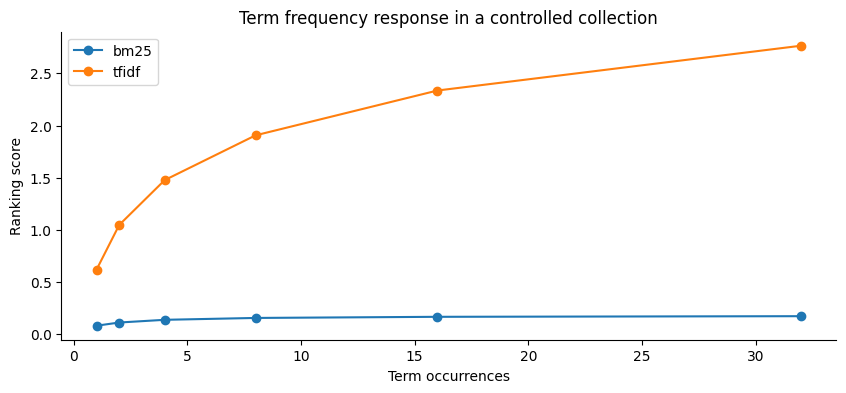

In [5]:
synthetic=[{'id':str(tf),'title':'Fixture','content':('retrieval '*tf)+('filler '*30)} for tf in [1,2,4,8,16,32]]
fixture=Index(synthetic);rows=[]
for algorithm in ['bm25','tfidf']:
    for hit in fixture.search('retrieval',algorithm):rows.append({'algorithm':algorithm,'term_frequency':int(hit['id']),'score':hit['score']})
curve=pd.DataFrame(rows)
for algorithm,group in curve.groupby('algorithm'):
    group=group.sort_values('term_frequency');plt.plot(group.term_frequency,group.score,marker='o',label=algorithm)
plt.legend();plt.xlabel('Term occurrences');plt.ylabel('Ranking score');plt.title('Term frequency response in a controlled collection');plt.show()

## Bounded scaling experiment

Replicate original documents under unique IDs to measure index-building and retrieval costs. This repeats vocabulary and content, so it is a workload probe rather than a realistic web corpus.

,documents,build_ms,query_p50_ms,query_p95_ms,stored_token_positions
0,12,1.971,0.021,0.033,325
1,120,1.890,0.188,0.216,3250
2,1200,19.705,2.349,2.640,32500
3,6000,202.487,7.471,9.268,162500


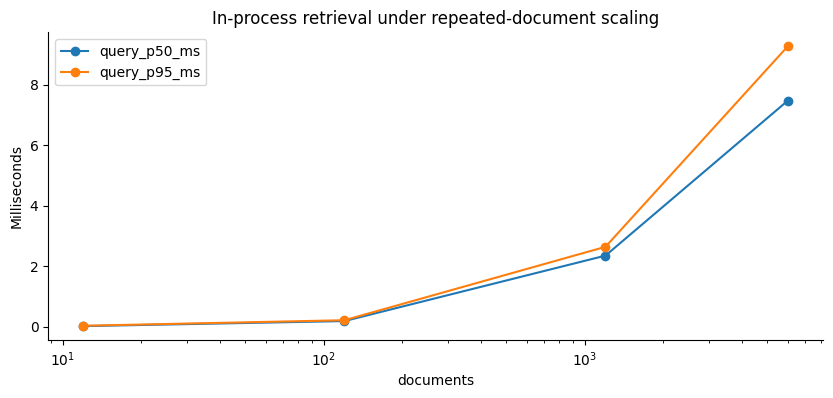

In [6]:
measurements=[]
for multiplier in [1,10,100,500]:
    expanded=[dict(doc,id=str(i*len(documents)+j+1),url=f'https://example.org/fixture/{i}/{j}') for i in range(multiplier) for j,doc in enumerate(documents)]
    start=time.perf_counter();scaled=Index(expanded);build_ms=(time.perf_counter()-start)*1000
    latencies=[]
    for _ in range(15):
        start=time.perf_counter();scaled.search('retrieval ranking');latencies.append((time.perf_counter()-start)*1000)
    positions=sum(len(p) for posting in scaled.postings.values() for p in posting.values())
    measurements.append({'documents':len(expanded),'build_ms':build_ms,'query_p50_ms':np.median(latencies),
                         'query_p95_ms':np.quantile(latencies,.95),'stored_token_positions':positions})
scaling=pd.DataFrame(measurements);display(scaling.round(3))
scaling.plot(x='documents',y=['query_p50_ms','query_p95_ms'],marker='o',logx=True);plt.ylabel('Milliseconds');plt.title('In-process retrieval under repeated-document scaling');plt.show()